# A look at some of the BBL's most iconic chases through predictive modelling

This report will look into which factors influence a batting team's likelihood of winning a match at any given stage during a chase, using Logistic Regression. This model has been used to view the ball-by-ball win probability of some of the BBL's most iconic run chases. 

**Contents**

1. Data loading
2. Feature Engineering
3. Selecting the matches
4. Team strength (Elo)
5. Model: forward-in-time train/test split
6. The chases

In [17]:
# Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import log_loss, accuracy_score
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LinearRegression

## 1. Data Loading

Data for the project was sourced from Cricsheet at https://cricsheet.org/ (Licence details https://cricsheet.org/about/). Raw JSON data was parsed and converted into a master .CSV file for the purposes of this analysis. The .CSV includes ball-by-ball data for each ball in BBL history up until the end of BBL|15. 

In [18]:
merged_df = pd.read_csv("data/bbl_deliveries.csv", low_memory=False)

matches = merged_df.drop_duplicates('match_id')[
    ['match_id', 'date', 'team1', 'team2', 'winner']
]
print(merged_df.shape, matches.shape)

(153250, 34) (662, 5)


## 2. Feature engineering

Everything is calculated within each innings, in ball order. Wides and no-balls are extra deliveries, therefore do not use up one of the 120 legal balls.

In [19]:
# Sorting entries by ball order
merged_df = merged_df.sort_values(['match_id', 'innings_num', 'over', 'ball_in_over']).reset_index(drop=True)

# A delivery is legal unless it is a wide or a no-ball
merged_df['is_legal_delivery'] = ~(
    (merged_df['wides'].fillna(0) > 0) | (merged_df['noballs'].fillna(0) > 0)
)

# Running totals within each innings
merged_df['is_wicket'] = merged_df['is_wicket'].fillna(False).astype(bool).astype(int)
merged_df['current_score'] = merged_df.groupby(['match_id', 'innings_num'])['runs_total'].cumsum()
merged_df['wickets_lost'] = merged_df.groupby(['match_id', 'innings_num'])['is_wicket'].cumsum()
merged_df['balls_bowled'] = merged_df.groupby(['match_id', 'innings_num'])['is_legal_delivery'].cumsum()
merged_df['balls_remaining'] = (
    merged_df['overs_per_innings'] * merged_df['balls_per_over']
) - merged_df['balls_bowled']

In [20]:
# Target = the first-innings total + 1.
targets = merged_df[merged_df['innings_num'] == 1].groupby('match_id')['current_score'].max().reset_index()
targets.columns = ['match_id', 'target']
targets['target'] = targets['target'] + 1

merged_df = merged_df.merge(targets, on='match_id', how='left')
merged_df.loc[merged_df['innings_num'] == 1, 'target'] = np.nan   # no target while batting first

# Runs required and required run rate only exist in the second innings
merged_df['runs_required'] = np.where(
    merged_df['innings_num'] == 2,
    merged_df['target'] - merged_df['current_score'],
    np.nan
)

merged_df['required_run_rate'] = np.where(
    (merged_df['innings_num'] == 2) & (merged_df['balls_remaining'] > 0),
    merged_df['runs_required'].clip(lower=0) / (merged_df['balls_remaining'] / 6),
    np.nan
)

# Current run rate
merged_df['current_run_rate'] = np.where(
    merged_df['balls_bowled'] > 0,
    merged_df['current_score'] / (merged_df['balls_bowled'] / 6),
    np.nan
)

In [21]:
# Rolling windows over the last n LEGAL balls: runs (momentum) and wickets (recent collapse)
# Runs scored off wides and no-balls count towards the window, but those deliveries do not use up one of the n balls.

def last_n_legal_balls(df, col, n):
    key = ['match_id', 'innings_num']
    cum = df.groupby(key)[col].cumsum()
    ref = df.loc[df['is_legal_delivery'], key + ['balls_bowled']].copy()
    ref['cum_then'] = cum.loc[ref.index].values
    ref = ref.rename(columns={'balls_bowled': 'start_ball'})
    look = df[key + ['balls_bowled']].copy()
    look['start_ball'] = look['balls_bowled'] - n
    look = look.merge(ref, on=key + ['start_ball'], how='left')
    return cum.values - look['cum_then'].fillna(0).values   # no ball n before = nothing to subtract

merged_df['runs_last_6_legal_balls'] = last_n_legal_balls(merged_df, 'runs_total', 6)
merged_df['wickets_last_2_overs'] = last_n_legal_balls(merged_df, 'is_wicket', 12)   # last 12 legal balls

## 3. Selecting the matches

Only regular 20-over matches with a clear winner are used to reduce noise. Super Overs, DLS-affected, abandoned and no-result matches are removed.

In [22]:
# Dropping Super Over Innings
super_over_matches = merged_df.loc[merged_df['innings_num'] > 2, 'match_id'].unique()
df = merged_df[merged_df['innings_num'].isin([1, 2])].copy()
df = df[~df['match_id'].isin(super_over_matches)]

# Removing Shortened/DLS affected matches
df = df[df['overs_per_innings'] == 20]
df = df[df['method'].isna()]

# Drop no-results/abandoned matches (no winner recorded)
df = df.dropna(subset=['winner'])

# The label: 1 if the team batting on this ball went on to win the match, else 0
df['batting_team_won'] = (df['batting_team'] == df['winner']).astype(int)

In [23]:
# Label check: exactly one team wins each match, so the innings 1 and innings 2 labels must be opposites
# This should print 1.0
check = df.groupby(['match_id', 'innings_num'])['batting_team_won'].first().unstack()
print((check[1] + check[2] == 1).mean())

1.0


In [24]:
# The modelling dataset: second-innings balls where the chase is still live
chase = df[
    (df['innings_num'] == 2) &
    (df['runs_required'] > 0) &      # chase not yet won
    (df['balls_remaining'] > 0) &    # innings not yet over
    (df['wickets_lost'] < 10)        # not all out
].copy()

assert chase[['runs_last_6_legal_balls', 'wickets_last_2_overs']].notna().all().all()

## 4. Team strength (Elo)

Every team starts on 1500 and ratings update after each match, in date order. Each match uses the rating from before it was played. This means a cannot leak into it's own feature. 

In [25]:
teams = pd.unique(matches[['team1', 'team2']].values.ravel())
elo = {team: 1500 for team in teams}
K = 24

# Process matches in chronological order (ratings depend on every earlier result)
matches_sorted = matches.sort_values(['date', 'match_id']).copy()
pre_match_elo_rows = []

for _, row in matches_sorted.iterrows():
    t1, t2, winner = row['team1'], row['team2'], row['winner']
    r1, r2 = elo[t1], elo[t2]

    # Recording each team's ELO rating before the result is applied
    pre_match_elo_rows.append({'match_id': row['match_id'], 'team': t1, 'pre_match_elo': r1})
    pre_match_elo_rows.append({'match_id': row['match_id'], 'team': t2, 'pre_match_elo': r2})

    expected_1 = 1 / (1 + 10 ** ((r2 - r1) / 400))
    expected_2 = 1 - expected_1
    actual_1 = 1 if winner == t1 else (0.5 if pd.isna(winner) else 0)
    actual_2 = 1 if winner == t2 else (0.5 if pd.isna(winner) else 0)

    elo[t1] = r1 + K * (actual_1 - expected_1)
    elo[t2] = r2 + K * (actual_2 - expected_2)

elo_long = pd.DataFrame(pre_match_elo_rows)

# The team bowling in the second innings
chase['bowling_team'] = np.where(chase['batting_team'] == chase['team1'], chase['team2'], chase['team1'])

# Attach each side's pre-match Elo to every ball of the chase
chase = chase.merge(
    elo_long.rename(columns={'team': 'batting_team', 'pre_match_elo': 'batting_team_elo'}),
    on=['match_id', 'batting_team'],
    how='left'
)
chase = chase.merge(
    elo_long.rename(columns={'team': 'bowling_team', 'pre_match_elo': 'bowling_team_elo'}),
    on=['match_id', 'bowling_team'],
    how='left'
)
chase['elo_diff'] = chase['batting_team_elo'] - chase['bowling_team_elo']

# Checks: no missing values, row count unchanged by the merges, appropriate spread of ratings
print("Missing elo_diff:", chase['elo_diff'].isna().sum())
print("chase shape:", chase.shape)
print(elo_long['pre_match_elo'].describe())

Missing elo_diff: 0
chase shape: (69321, 49)
count    1324.000000
mean     1503.053372
std        59.336681
min      1358.193238
25%      1465.261046
50%      1499.150032
75%      1539.601728
max      1673.417725
Name: pre_match_elo, dtype: float64


## 5. Model: forward-in-time train/test split

The model is trained on the oldest 80% of matches and tested on the most recent 20%. The split is by match, so no match appears on both sides.

Correlation between each variable is also checked.

In [ ]:
features = ['runs_required', 'runs_last_6_legal_balls', 'wickets_last_2_overs',
            'wickets_lost', 'required_run_rate', 'elo_diff']

# Order matches by date and hold out the most recent ~20% as the test set
match_dates = (
    chase.groupby('match_id')['date'].first()
    .pipe(pd.to_datetime)
    .rename('date')
    .reset_index()
    .sort_values(['date', 'match_id'])
)
n_test = int(0.2 * len(match_dates))
test_ids = match_dates['match_id'].iloc[-n_test:]

train = chase[~chase['match_id'].isin(test_ids)]
test = chase[chase['match_id'].isin(test_ids)]

In [27]:
# Correlation between features (training data only)
corr = train[features].corr()
print(corr.round(2))

                         runs_required  runs_last_6_legal_balls  \
runs_required                     1.00                    -0.22   
runs_last_6_legal_balls          -0.22                     1.00   
wickets_last_2_overs             -0.09                    -0.21   
wickets_lost                     -0.49                    -0.00   
required_run_rate                -0.04                    -0.00   
elo_diff                         -0.03                     0.03   

                         wickets_last_2_overs  wickets_lost  \
runs_required                           -0.09         -0.49   
runs_last_6_legal_balls                 -0.21         -0.00   
wickets_last_2_overs                     1.00          0.50   
wickets_lost                             0.50          1.00   
required_run_rate                        0.16          0.37   
elo_diff                                -0.05         -0.04   

                         required_run_rate  elo_diff  
runs_required                    

In [28]:
print("Train:", match_dates['date'].iloc[:-n_test].min().date(), "to", match_dates['date'].iloc[:-n_test].max().date(),
      f"({len(match_dates) - n_test} matches)")
print("Test: ", match_dates['date'].iloc[-n_test:].min().date(), "to", match_dates['date'].iloc[-n_test:].max().date(),
      f"({n_test} matches)")

X_train, y_train = train[features], train['batting_team_won']
X_test, y_test = test[features], test['batting_team_won']

Train: 2011-12-16 to 2023-01-24 (492 matches)
Test:  2023-01-25 to 2026-01-25 (123 matches)


In [29]:
# Scale the features, then fit logistic regression (the scaler is learned from the training data only)
model = make_pipeline(StandardScaler(), LogisticRegression())
model.fit(X_train, y_train)

# Coefficients are on the standardised scale, so they can be compared with each other
coefs = pd.Series(model[-1].coef_[0], index=features)
print(coefs)

runs_required             -1.366056
runs_last_6_legal_balls    0.035432
wickets_last_2_overs      -0.061676
wickets_lost              -1.205394
required_run_rate         -5.723949
elo_diff                   0.360254
dtype: float64


In [30]:
probs = model.predict_proba(X_test)[:, 1]   # P(batting team wins)

print("Log loss:", log_loss(y_test, probs))
print("Accuracy:", accuracy_score(y_test, probs > 0.5))

# Baseline: always predict the win rate seen in training, ignoring the match state
baseline = np.full(len(y_test), y_train.mean())
print("Baseline log loss:", log_loss(y_test, baseline))

# Average predicted win rate vs what actually happened in the test seasons
print("Mean predicted win rate:", probs.mean(), "| actual:", y_test.mean())

Log loss: 0.4647584185892882
Accuracy: 0.7745765165773852
Baseline log loss: 0.7026554321223609
Mean predicted win rate: 0.5240387559058611 | actual: 0.6316056174895034


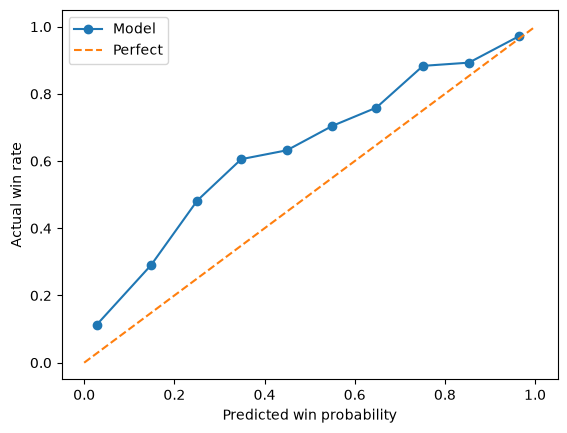

In [31]:
# Calibration plot on the test seasons: do predicted probabilities match how often teams actually won?
frac_won, mean_pred = calibration_curve(y_test, probs, n_bins=10)
plt.plot(mean_pred, frac_won, marker='o', label='Model')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfect')
plt.xlabel('Predicted win probability')
plt.ylabel('Actual win rate')
plt.legend()
plt.show()

## 6. The chases

Here, the win probability after every legal ball of each chase is plotted, from the model above. A helper function is created to generate plots for the required matches. 

Match 1023611: Sydney Thunder chasing v Melbourne Stars, 2017-01-04 (season 2016/17). Winner: Sydney Thunder


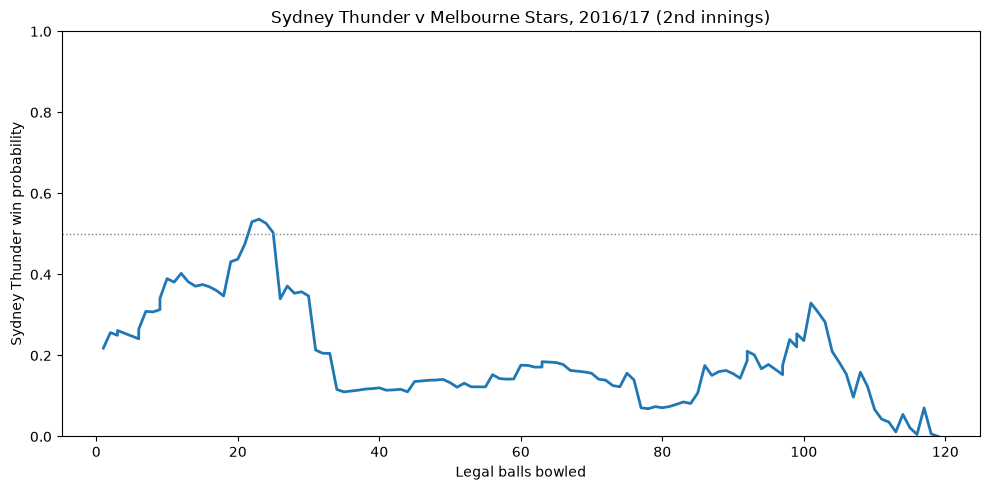

Match 756795: Melbourne Stars chasing v Perth Scorchers, 2015-01-21 (season 2014/15). Winner: Melbourne Stars


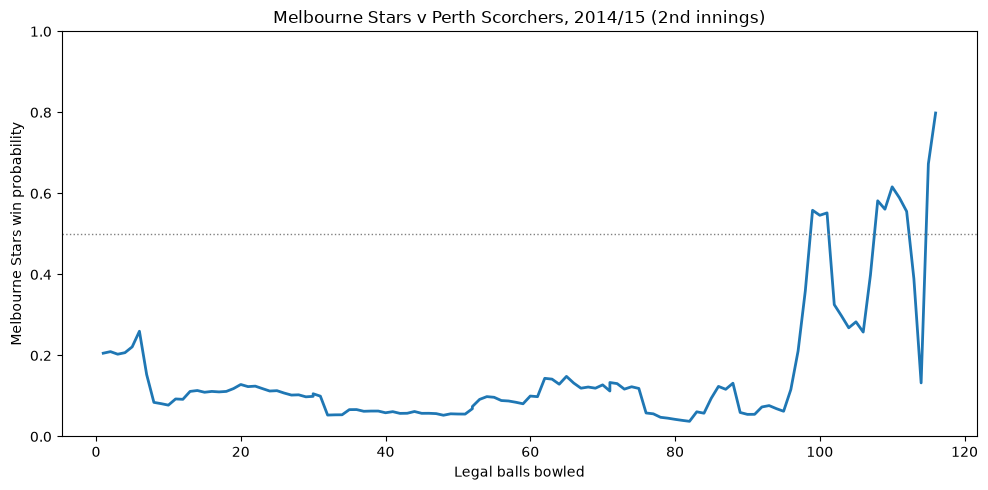

Match 897721: Adelaide Strikers chasing v Sydney Sixers, 2015-12-31 (season 2015/16). Winner: Adelaide Strikers


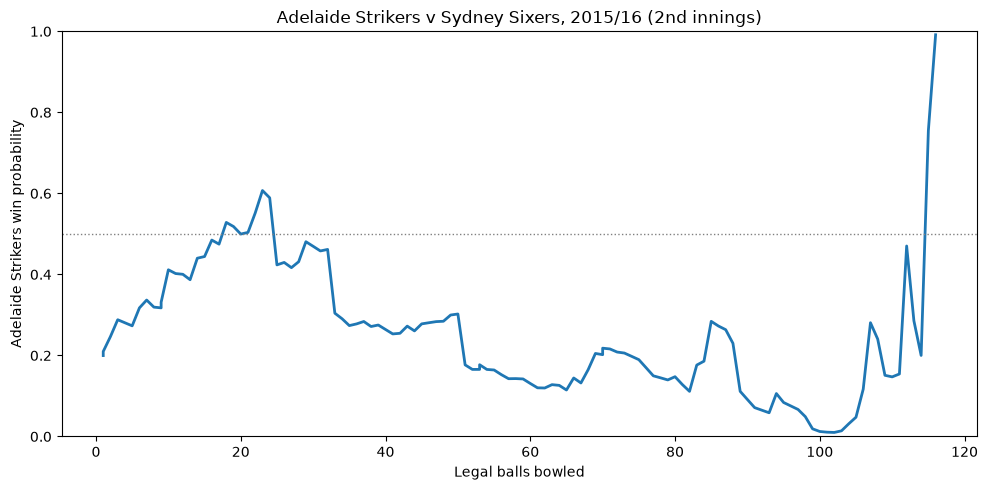

Match 1493243: Brisbane Heat chasing v Perth Scorchers, 2025-12-19 (season 2025/26). Winner: Brisbane Heat


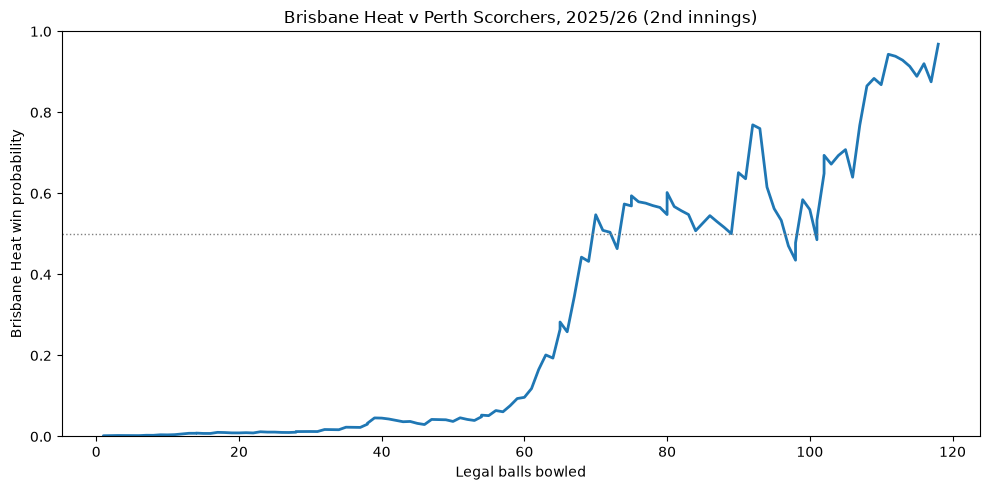

Match 1493272: Hobart Hurricanes chasing v Brisbane Heat, 2026-01-14 (season 2025/26). Winner: Brisbane Heat


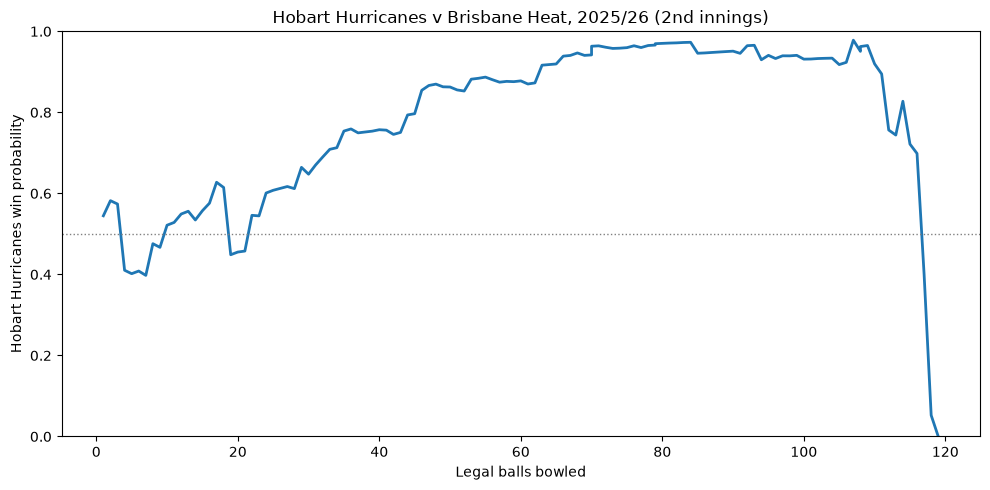

In [32]:
def plot_chase(match_id, data=chase, model=model, features=features):
    m = data[data['match_id'] == match_id].sort_values(['over', 'ball_in_over'])
    if m.empty:
        print(f"Match {match_id} is not in the chase dataset (removed by the filters).")
        return

    team = m['batting_team'].iloc[0]      # the chasing side
    opp = m['bowling_team'].iloc[0]
    season = m['season'].iloc[0]
    date = m['date'].iloc[0]
    winner = m['winner'].iloc[0]
    win_prob = model.predict_proba(m[features])[:, 1]

    print(f"Match {match_id}: {team} chasing v {opp}, {date} (season {season}). Winner: {winner}")

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(m['balls_bowled'].values, win_prob, linewidth=2)
    ax.axhline(0.5, color='grey', linestyle=':', linewidth=1)
    ax.set_ylim(0, 1)
    ax.set_xlabel('Legal balls bowled')
    ax.set_ylabel(f'{team} win probability')
    ax.set_title(f'{team} v {opp}, {season} (2nd innings)')
    fig.tight_layout()
    plt.show()


# Thunder v Stars (BBL|06), Stars v Scorchers (BBL|04), Strikers v Sixers (BBL|05), Heat v Scorchers (BBL|15), Hurricanes v Heat (BBL|15)
for chase_id in [1023611, 756795, 897721,1493243,1493272]:
    plot_chase(chase_id)